# Experiment-6: GloVe Word Embeddings and N-gram Language Model

## 6.1. Implement the GloVe (Global Vectors for Word Representation) algorithm to generate word embeddings from the text corpus and find the most similar words of "King".
(Two separate codes: 1. Without using any pretrained model and 2. Using a pretrained model (Gensim))

### Loading the corpus (`glove_corpus.txt`)

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from collections import Counter, defaultdict

In [2]:
with open("glove_corpus.txt", "r", encoding="utf-8") as f:
    corpus_text = f.read()

sentences = [re.findall(r"[a-z]+", line.lower()) for line in corpus_text.splitlines() if line.strip()]

print("Sentences:", len(sentences))
sentences[:5]

Sentences: 24


[['the', 'king', 'rules', 'the', 'kingdom'],
 ['the', 'queen', 'rules', 'the', 'kingdom'],
 ['the', 'king', 'is', 'a', 'powerful', 'man'],
 ['the', 'queen', 'is', 'a', 'wise', 'woman'],
 ['the', 'man', 'is', 'strong', 'and', 'brave']]

### 1. Without using any pretrained model (GloVe implemented from scratch)

GloVe learns vectors so that their dot product matches the log of how often two words co-occur:

$$J = \sum_{i,j} f(X_{ij}) \left( w_i^T \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2, \qquad f(x) = \begin{cases} (x / x_{max})^{\alpha} & x < x_{max} \\ 1 & \text{otherwise} \end{cases}$$

**Step 1 – vocabulary.** Very common function words (*the, a, is, ...*) co-occur with everything, so they are dropped before counting.

In [3]:
stop_words = {"the", "a", "an", "is", "and", "of", "in", "at", "to", "on"}

tokenized = [[w for w in s if w not in stop_words] for s in sentences]

word_counts = Counter(w for s in tokenized for w in s)
vocab = sorted(word_counts)
word2idx = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

print("Vocabulary size:", V)

Vocabulary size: 61


**Step 2 – co-occurrence matrix.** Every pair of words within the window adds `1 / distance` to `X[i, j]` (closer words count more).

In [4]:
window_size = 4
X = np.zeros((V, V))

for sent in tokenized:
    for i, word in enumerate(sent):
        for j in range(max(0, i - window_size), min(len(sent), i + window_size + 1)):
            if i != j:
                X[word2idx[word], word2idx[sent[j]]] += 1.0 / abs(i - j)

df_cooc = pd.DataFrame(X, index=vocab, columns=vocab)
df_cooc.loc[["king", "queen", "man", "woman"], ["rules", "kingdom", "palace", "royal", "strong", "kind"]]

,rules,kingdom,palace,royal,strong,kind
king,1.0,0.500000,0.333333,0.5,0.0,0.0
queen,1.0,0.500000,0.333333,0.5,0.0,0.0
man,0.0,0.333333,0.000000,0.0,1.0,0.0
woman,0.0,0.500000,0.000000,0.0,0.0,0.5


**Step 3 – training.** Weighted least squares on the non-zero entries of `X`, optimised with AdaGrad.

In [5]:
def train_glove(X, dim=20, x_max=10, alpha=0.75, lr=0.05, epochs=500, seed=42):
    rng = np.random.default_rng(seed)
    V = X.shape[0]

    W = (rng.random((V, dim)) - 0.5) / dim          # main word vectors
    W_ctx = (rng.random((V, dim)) - 0.5) / dim      # context word vectors
    b = np.zeros(V)
    b_ctx = np.zeros(V)

    # AdaGrad accumulators
    gW, gW_ctx = np.ones((V, dim)), np.ones((V, dim))
    gb, gb_ctx = np.ones(V), np.ones(V)

    rows, cols = np.nonzero(X)
    log_x = np.log(X[rows, cols])
    weights = np.minimum(1.0, (X[rows, cols] / x_max) ** alpha)

    losses = []
    for epoch in range(epochs):
        total_loss = 0.0
        for k in rng.permutation(len(rows)):
            i, j = rows[k], cols[k]
            diff = W[i] @ W_ctx[j] + b[i] + b_ctx[j] - log_x[k]
            total_loss += 0.5 * weights[k] * diff ** 2

            grad = weights[k] * diff
            grad_wi = grad * W_ctx[j]
            grad_wj = grad * W[i]

            W[i] -= lr * grad_wi / np.sqrt(gW[i])
            W_ctx[j] -= lr * grad_wj / np.sqrt(gW_ctx[j])
            b[i] -= lr * grad / np.sqrt(gb[i])
            b_ctx[j] -= lr * grad / np.sqrt(gb_ctx[j])

            gW[i] += grad_wi ** 2
            gW_ctx[j] += grad_wj ** 2
            gb[i] += grad ** 2
            gb_ctx[j] += grad ** 2
        losses.append(total_loss)

    return W + W_ctx, losses     # final embedding = main + context vectors


embeddings, losses = train_glove(X)

print("Embedding matrix shape:", embeddings.shape)
print("Loss: first epoch = %.4f, last epoch = %.4f" % (losses[0], losses[-1]))

Embedding matrix shape: (61, 20)
Loss: first epoch = 3.7729, last epoch = 0.1758


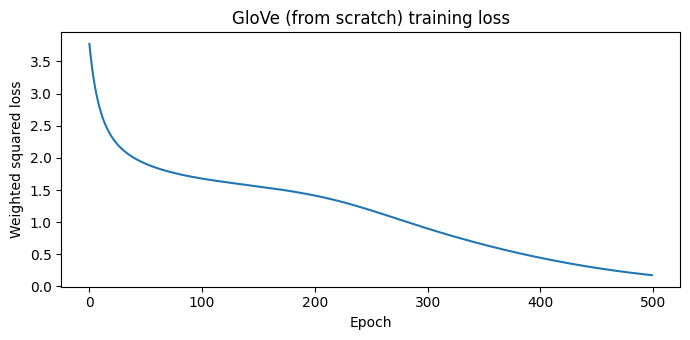

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Weighted squared loss")
plt.title("GloVe (from scratch) training loss")
plt.tight_layout()
plt.show()

**Step 4 – most similar words to "king"** (cosine similarity).

In [7]:
def most_similar(word, embeddings, topn=5):
    vec = embeddings[word2idx[word]]
    norms = np.linalg.norm(embeddings, axis=1) * np.linalg.norm(vec)
    sims = embeddings @ vec / norms
    order = [i for i in np.argsort(-sims) if vocab[i] != word][:topn]
    return [(vocab[i], round(float(sims[i]), 4)) for i in order]


print("Vector for 'king':")
print(np.round(embeddings[word2idx["king"]], 4))

df_glove_scratch = pd.DataFrame(most_similar("king", embeddings), columns=["Word", "Cosine Similarity"])
df_glove_scratch

Vector for 'king':
[ 0.2694 -0.3289 -0.2931 -0.1031  0.1533  0.028  -0.2329 -0.0911  0.1534
  0.5189  0.2258 -0.3065 -0.7701  0.3849 -0.409  -0.2471 -0.686   0.1428
  0.6541  0.1576]


,Word,Cosine Similarity
0,queen,0.9803
1,son,0.9238
2,wise,0.8540
3,lives,0.8334
4,powerful,0.8323


### 2. Using a pretrained model (Gensim)

`glove-wiki-gigaword-100` – 100-dimensional GloVe vectors trained by Stanford on Wikipedia + Gigaword (400k words), loaded through `gensim.downloader`.

In [8]:
import gensim.downloader as api

glove_pretrained = api.load("glove-wiki-gigaword-100")

print("Vocabulary size:", len(glove_pretrained.index_to_key))
print("Vector size:", glove_pretrained.vector_size)

Vocabulary size: 400000
Vector size: 100


In [9]:
print("Vector for 'king' (first 10 values):")
print(glove_pretrained["king"][:10])

df_glove_pretrained = pd.DataFrame(glove_pretrained.most_similar("king", topn=5), columns=["Word", "Cosine Similarity"])
df_glove_pretrained

Vector for 'king' (first 10 values):
[-0.32307 -0.87616  0.21977  0.25268  0.22976  0.7388  -0.37954 -0.35307
 -0.84369 -1.1113 ]


,Word,Cosine Similarity
0,prince,0.768233
1,queen,0.750769
2,son,0.702089
3,brother,0.698578
4,monarch,0.697789


Restricting the pretrained model to the words of our corpus gives a direct comparison with the scratch model:

In [10]:
corpus_vocab = [w for w in vocab if w in glove_pretrained and w != "king"]
pretrained_in_corpus = sorted(
    ((w, round(float(glove_pretrained.similarity("king", w)), 4)) for w in corpus_vocab),
    key=lambda x: -x[1],
)[:5]

pd.concat(
    [df_glove_scratch.add_prefix("Scratch "),
     pd.DataFrame(pretrained_in_corpus, columns=["Word", "Cosine Similarity"]).add_prefix("Pretrained ")],
    axis=1,
)

,Scratch Word,Scratch Cosine Similarity,Pretrained Word,Pretrained Cosine Similarity
0,queen,0.9803,prince,0.7682
1,son,0.9238,queen,0.7508
2,wise,0.8540,son,0.7021
3,lives,0.8334,kingdom,0.6811
4,powerful,0.8323,royal,0.6034


In [11]:
# classic analogy check with the pretrained vectors: king - man + woman = ?
glove_pretrained.most_similar(positive=["king", "woman"], negative=["man"], topn=3)

[('queen', 0.7698541283607483),
 ('monarch', 0.6843380331993103),
 ('throne', 0.6755736470222473)]

## 6.2. Implement a statistical language model from scratch using the N-gram approach to predict the next word in a sequence based on the preceding words in a text corpus.

In [12]:
ngram_corpus = (
    "natural language processing is a branch of artificial intelligence. "
    "natural language processing enables computers to understand human language. "
    "machine learning is a branch of artificial intelligence. "
    "deep learning is a part of machine learning. "
    "language models learn patterns from text data. "
    "a language model predicts the next word in a sentence. "
    "natural language processing uses language models. "
    "artificial intelligence includes machine learning and deep learning."
)

# one list of tokens per sentence, padded with start / end markers
ngram_sentences = [s.split() for s in ngram_corpus.split(".") if s.strip()]
ngram_vocab = sorted({w for s in ngram_sentences for w in s} | {"</s>"})

print("Sentences:", len(ngram_sentences))
print("Vocabulary size:", len(ngram_vocab))

Sentences: 8
Vocabulary size: 35


### Building the N-gram counts
`counts[context][next_word]` – how often `next_word` follows the `n-1` word `context`.

In [13]:
class NGramModel:
    def __init__(self, n, k=0.0):
        self.n = n          # order of the model (2 = bigram, 3 = trigram, ...)
        self.k = k          # add-k smoothing (0 = plain maximum likelihood)
        self.counts = defaultdict(Counter)

    def fit(self, sentences):
        for sent in sentences:
            tokens = ["<s>"] * (self.n - 1) + sent + ["</s>"]
            for i in range(self.n - 1, len(tokens)):
                context = tuple(tokens[i - self.n + 1:i])
                self.counts[context][tokens[i]] += 1
        return self

    def prob(self, context, word):
        """P(word | context) = (C(context, word) + k) / (C(context) + k * |V|)"""
        context = tuple(context[-(self.n - 1):])
        followers = self.counts[context]
        return (followers[word] + self.k) / (sum(followers.values()) + self.k * len(ngram_vocab))

    def predict_next(self, text, topn=3):
        tokens = ["<s>"] * (self.n - 1) + text.lower().split()
        context = tuple(tokens[-(self.n - 1):])
        total = sum(self.counts[context].values())
        if total == 0:
            return []
        return [(w, round(c / total, 4)) for w, c in self.counts[context].most_common(topn)]

    def generate(self, text, max_words=10):
        words = text.lower().split()
        for _ in range(max_words):
            prediction = self.predict_next(" ".join(words), topn=1)
            if not prediction or prediction[0][0] == "</s>":
                break
            words.append(prediction[0][0])
        return " ".join(words)

In [14]:
bigram = NGramModel(n=2).fit(ngram_sentences)
trigram = NGramModel(n=3).fit(ngram_sentences)

# bigram table for a few contexts
pd.DataFrame(
    [(" ".join(ctx), w, c, round(c / sum(f.values()), 3))
     for ctx in [("natural",), ("language",), ("machine",), ("artificial",)]
     for f in [bigram.counts[ctx]] for w, c in f.most_common()],
    columns=["Context", "Next word", "Count", "P(next | context)"],
)

,Context,Next word,Count,P(next | context)
0,natural,language,3,1.000
1,language,processing,3,0.429
2,language,models,2,0.286
3,language,</s>,1,0.143
4,language,model,1,0.143
5,machine,learning,3,1.000
6,artificial,intelligence,3,1.000


### Predicting the next word

In [15]:
test_inputs = [
    "natural language",
    "machine",
    "deep learning is",
    "artificial intelligence",
    "a language model predicts the",
    "language models learn",
]

rows = []
for text in test_inputs:
    rows.append((text, bigram.predict_next(text), trigram.predict_next(text)))

pd.DataFrame(rows, columns=["Input", "Bigram prediction (word, P)", "Trigram prediction (word, P)"])

,Input,"Bigram prediction (word, P)","Trigram prediction (word, P)"
0,natural language,"[(processing, 0.4286), (models, 0.2857), (</s>...","[(processing, 1.0)]"
1,machine,"[(learning, 1.0)]","[(learning, 1.0)]"
2,deep learning is,"[(a, 1.0)]","[(a, 1.0)]"
3,artificial intelligence,"[(</s>, 0.6667), (includes, 0.3333)]","[(</s>, 0.6667), (includes, 0.3333)]"
4,a language model predicts the,"[(next, 1.0)]","[(next, 1.0)]"
5,language models learn,"[(patterns, 1.0)]","[(patterns, 1.0)]"


### Generating a sequence (greedy, most probable next word each step)

In [16]:
for seed in ["natural", "deep learning", "a language"]:
    print(f"Bigram : {seed!r:18} -> {bigram.generate(seed)}")
    print(f"Trigram: {seed!r:18} -> {trigram.generate(seed)}")
    print()

Bigram : 'natural'          -> natural language processing is a branch of artificial intelligence
Trigram: 'natural'          -> natural language processing is a branch of artificial intelligence

Bigram : 'deep learning'    -> deep learning is a branch of artificial intelligence
Trigram: 'deep learning'    -> deep learning is a branch of artificial intelligence

Bigram : 'a language'       -> a language processing is a branch of artificial intelligence
Trigram: 'a language'       -> a language model predicts the next word in a sentence



### Evaluating with perplexity

Perplexity on a held-out sentence: $PP = \exp\left(-\frac{1}{N}\sum \log P(w_i \mid w_{i-n+1}^{i-1})\right)$. Unseen n-grams get zero probability under plain MLE, so add-1 (Laplace) smoothing is used here.

In [17]:
def perplexity(model, sentence):
    tokens = ["<s>"] * (model.n - 1) + sentence.split() + ["</s>"]
    log_prob = 0.0
    for i in range(model.n - 1, len(tokens)):
        log_prob += np.log(model.prob(tokens[i - model.n + 1:i], tokens[i]))
    return float(np.exp(-log_prob / (len(tokens) - model.n + 1)))


smoothed = {n: NGramModel(n=n, k=1.0).fit(ngram_sentences) for n in (1, 2, 3)}

test_sentences = [
    "natural language processing is a branch of artificial intelligence",   # seen
    "deep learning is a branch of artificial intelligence",                 # new combination
]

pd.DataFrame(
    [(s, *[round(perplexity(smoothed[n], s), 2) for n in (1, 2, 3)]) for s in test_sentences],
    columns=["Sentence", "Unigram PP", "Bigram PP", "Trigram PP"],
)

,Sentence,Unigram PP,Bigram PP,Trigram PP
0,natural language processing is a branch of art...,22.96,11.71,12.59
1,deep learning is a branch of artificial intell...,24.04,12.67,14.40
